# Smart-Home Energy Consumption — Bayesian Network

Six variables, one DAG, three models (expert, MLE, Bayesian/BDeu).

**Structure:** `DayType → Occupancy`, `Weather → AC ← Occupancy`, `Occupancy → Load`, `AC → Energy ← Load`

In [1]:
import itertools
import warnings, logging
warnings.filterwarnings("ignore"); logging.disable(logging.WARNING)

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.estimators import MaximumLikelihoodEstimator, BayesianEstimator

pd.set_option("display.precision", 4)

## Part A — Expert network
### A1–A2. Structure, CPTs and validity check

In [2]:
# Every variable and its states. The FIRST state is the one the tables give P() for.
STATES = {
    "Weather":   ["Hot", "Mild", "Cold"],
    "DayType":   ["Weekday", "Weekend"],
    "Occupancy": ["High", "Low"],
    "AC":        ["On", "Off"],
    "Load":      ["Heavy", "Light"],
    "Energy":    ["High", "Low"],
}
EDGES = [("DayType", "Occupancy"),
         ("Weather", "AC"), ("Occupancy", "AC"),
         ("Occupancy", "Load"),
         ("AC", "Energy"), ("Load", "Energy")]


def binary_cpd(var, p_first, parents):
    # p_first[i] = P(var = first state | i-th parent combination).
    # pgmpy orders parent combinations with the LAST parent changing fastest,
    # which is exactly the row order of the tables in the problem statement.
    return TabularCPD(var, 2, [p_first, [1 - p for p in p_first]],
                      evidence=parents,
                      evidence_card=[len(STATES[p]) for p in parents],
                      state_names={v: STATES[v] for v in [var, *parents]})


cpds = [
    TabularCPD("Weather", 3, [[0.50], [0.30], [0.20]], state_names={"Weather": STATES["Weather"]}),
    TabularCPD("DayType", 2, [[0.70], [0.30]],         state_names={"DayType": STATES["DayType"]}),
    binary_cpd("Occupancy", [0.45, 0.80], ["DayType"]),                       # Weekday, Weekend
    binary_cpd("AC", [0.90, 0.60, 0.40, 0.15, 0.10, 0.05], ["Weather", "Occupancy"]),
    binary_cpd("Load", [0.75, 0.35], ["Occupancy"]),                          # High, Low
    binary_cpd("Energy", [0.92, 0.68, 0.55, 0.12], ["AC", "Load"]),           # (On,Heavy),(On,Light),(Off,Heavy),(Off,Light)
]

expert = DiscreteBayesianNetwork(EDGES)
expert.add_cpds(*cpds)

# Each column of a CPT is one parent configuration -> it must sum to 1.
for cpd in expert.get_cpds():
    col_sums = cpd.get_values().sum(axis=0)
    assert np.allclose(col_sums, 1), cpd.variable
    print(f"{cpd.variable:<10} {len(col_sums)} parent configs, all sum to 1")
print("check_model():", expert.check_model())

Weather    1 parent configs, all sum to 1
DayType    1 parent configs, all sum to 1
Occupancy  2 parent configs, all sum to 1
AC         6 parent configs, all sum to 1
Load       2 parent configs, all sum to 1
Energy     4 parent configs, all sum to 1
check_model(): True


In [3]:
print(expert.get_cpds("AC"))

+-----------+---------------------+-----+-----------------+----------------+
| Weather   | Weather(Hot)        | ... | Weather(Cold)   | Weather(Cold)  |
+-----------+---------------------+-----+-----------------+----------------+
| Occupancy | Occupancy(High)     | ... | Occupancy(High) | Occupancy(Low) |
+-----------+---------------------+-----+-----------------+----------------+
| AC(On)    | 0.9                 | ... | 0.1             | 0.05           |
+-----------+---------------------+-----+-----------------+----------------+
| AC(Off)   | 0.09999999999999998 | ... | 0.9             | 0.95           |
+-----------+---------------------+-----+-----------------+----------------+


### A3. Visualisation

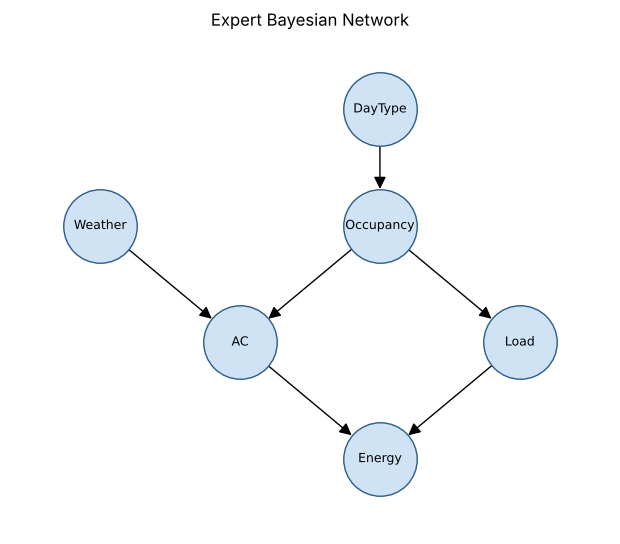

In [4]:
pos = {"Weather": (0, 1), "DayType": (2, 2), "Occupancy": (2, 1),
       "AC": (1, 0), "Load": (3, 0), "Energy": (2, -1)}
plt.figure(figsize=(6, 5))
nx.draw(nx.DiGraph(expert.edges()), pos, with_labels=True, node_size=2800,
        node_color="#cfe3f5", edgecolors="#2b5d8a", font_size=9,
        arrowsize=18, arrowstyle="-|>")
plt.title("Expert Bayesian Network")
plt.margins(0.15); plt.show()

### A4. Inference queries Q1–Q7 (exact, variable elimination)

In [5]:
# query name -> (target variable, target state, evidence)
QUERIES = {
    "Q1": ("Energy",  "High", {}),
    "Q2": ("Energy",  "High", {"Weather": "Hot"}),
    "Q3": ("Energy",  "High", {"DayType": "Weekend"}),
    "Q4": ("Energy",  "High", {"Weather": "Cold", "Occupancy": "High"}),
    "Q5": ("Weather", "Hot",  {"Energy": "High"}),
    "Q6": ("AC",      "On",   {"Energy": "High"}),
    "Q7": ("AC",      "On",   {"Energy": "High", "Load": "Heavy"}),
}


def prob(model, var, state, evidence=None):
    result = VariableElimination(model).query([var], evidence=evidence or {}, show_progress=False)
    return result.get_value(**{var: state})


def run_queries(model):
    return pd.Series({q: prob(model, *spec) for q, spec in QUERIES.items()})


expert_answers = run_queries(expert)
expert_answers.to_frame("Expert")

,Expert
Q1,0.5806
Q2,0.7063
Q3,0.6402
Q4,0.4843
Q5,0.6082
Q6,0.6929
Q7,0.6499


### A5. Explaining away (Q6 vs Q7)

`AC → Energy ← Load` is a **v-structure**. Seeing `Energy = High` makes AC more likely (Q6 > prior P(AC=On)).
Then also learning `Load = Heavy` gives a *second* explanation for the high bill, so the evidence no longer
needs AC to explain it — P(AC=On) drops (Q7 < Q6). The two causes compete once their common effect is observed.

In [6]:
prior_ac = prob(expert, "AC", "On")
print(f"P(AC=On)                         = {prior_ac:.4f}   (prior)")
print(f"P(AC=On | E=High)           [Q6] = {expert_answers.Q6:.4f}   (high bill -> AC more likely)")
print(f"P(AC=On | E=High, L=Heavy)  [Q7] = {expert_answers.Q7:.4f}   (heavy load explains it away)")

P(AC=On)                         = 0.4854   (prior)
P(AC=On | E=High)           [Q6] = 0.6929   (high bill -> AC more likely)
P(AC=On | E=High, L=Heavy)  [Q7] = 0.6499   (heavy load explains it away)


### A6. Q1 by hand

Everything flows through Occupancy, so sum over it last:

$$P(E{=}H)=\sum_{o} P(o)\sum_{a,l} P(a\mid o)\,P(l\mid o)\,P(E{=}H\mid a,l),\qquad P(A{=}On\mid o)=\sum_w P(w)\,P(On\mid w,o)$$

**Step 1 — Occupancy:** P(O=High) = 0.7·0.45 + 0.3·0.80 = 0.315 + 0.240 = **0.555**, so P(O=Low) = 0.445

**Step 2 — AC given Occupancy (Weather summed out):**
- P(On | High) = 0.5·0.90 + 0.3·0.40 + 0.2·0.10 = 0.45 + 0.12 + 0.02 = **0.590**
- P(On | Low) = 0.5·0.60 + 0.3·0.15 + 0.2·0.05 = 0.30 + 0.045 + 0.01 = **0.355**

**Step 3 — Energy given Occupancy** (AC and Load are independent given O):

| a, l | O = High: P(a)·P(l)·P(H\|a,l) | O = Low: P(a)·P(l)·P(H\|a,l) |
|---|---|---|
| On, Heavy  | 0.59·0.75·0.92 = 0.40710 | 0.355·0.35·0.92 = 0.11431 |
| On, Light  | 0.59·0.25·0.68 = 0.10030 | 0.355·0.65·0.68 = 0.15691 |
| Off, Heavy | 0.41·0.75·0.55 = 0.16913 | 0.645·0.35·0.55 = 0.12416 |
| Off, Light | 0.41·0.25·0.12 = 0.01230 | 0.645·0.65·0.12 = 0.05031 |
| **Sum**    | **0.68883** | **0.44569** |

**Step 4 — combine:** P(E=High) = 0.555·0.68883 + 0.445·0.44569 = 0.38230 + 0.19833 = **0.58063**

In [7]:
# Same four steps in plain Python, checked against pgmpy.
pW = {"Hot": .5, "Mild": .3, "Cold": .2}
pO = {"High": .7 * .45 + .3 * .80}; pO["Low"] = 1 - pO["High"]
pAC_on = {"High": {"Hot": .90, "Mild": .40, "Cold": .10},
          "Low":  {"Hot": .60, "Mild": .15, "Cold": .05}}
pHeavy = {"High": .75, "Low": .35}
pE_high = {("On", "Heavy"): .92, ("On", "Light"): .68, ("Off", "Heavy"): .55, ("Off", "Light"): .12}

q1 = 0
for o in ("High", "Low"):
    on = sum(pW[w] * pAC_on[o][w] for w in pW)
    pa = {"On": on, "Off": 1 - on}
    pl = {"Heavy": pHeavy[o], "Light": 1 - pHeavy[o]}
    inner = sum(pa[a] * pl[l] * pE_high[a, l] for a, l in pE_high)
    print(f"O={o:<4}  P(O)={pO[o]:.3f}  P(AC=On|O)={on:.3f}  P(E=High|O)={inner:.5f}")
    q1 += pO[o] * inner

print(f"\nBy hand: {q1:.6f}   pgmpy: {expert_answers.Q1:.6f}   match: {np.isclose(q1, expert_answers.Q1)}")

O=High  P(O)=0.555  P(AC=On|O)=0.590  P(E=High|O)=0.68883
O=Low   P(O)=0.445  P(AC=On|O)=0.355  P(E=High|O)=0.44569

By hand: 0.580631   pgmpy: 0.580631   match: True


## Part B — Conditional independence (d-separation)

| Statement | Paths between Weather and DayType / Load | Verdict |
|---|---|---|
| **W ⊥ D** | Only path: W → AC ← O ← D. AC is a collider and neither AC nor its descendant (Energy) is observed → **blocked**. | **Holds** |
| **W ⊥ D \| E** | Same path, but now Energy (a descendant of the collider AC) is observed → collider **opens**. (Path W→AC→E←L←O←D also opens: E is an observed collider.) | **Does not hold** |
| **W ⊥ L \| O** | W → AC ← O → L: O is an observed fork → **blocked**. W → AC → E ← L: E is an unobserved collider with no observed descendant → **blocked**. | **Holds** |

Numerical check below: if independence holds, adding the extra evidence must leave P(Weather=Hot | …) unchanged.

In [8]:
checks = [
    ("W ⊥ D",     {},                    {"DayType": "Weekend"}),
    ("W ⊥ D | E", {"Energy": "High"},    {"DayType": "Weekend"}),
    ("W ⊥ L | O", {"Occupancy": "High"}, {"Load": "Heavy"}),
    ("W ⊥ L | O", {"Occupancy": "Low"},  {"Load": "Light"}),
]
rows = []
for name, given, extra in checks:
    a = prob(expert, "Weather", "Hot", given)
    b = prob(expert, "Weather", "Hot", {**given, **extra})
    rows.append({"Statement": name,
                 "P(Hot | given)": a, "P(Hot | given + extra)": b,
                 "given": given or "-", "extra": extra,
                 "d-separated (pgmpy)": not expert.is_dconnected("Weather", list(extra)[0], observed=list(given)),
                 "numerically equal": np.isclose(a, b)})
pd.DataFrame(rows)

,Statement,P(Hot | given),P(Hot | given + extra),given,extra,d-separated (pgmpy),numerically equal
0,W ⊥ D,0.5000,0.5000,-,{'DayType': 'Weekend'},True,True
1,W ⊥ D | E,0.6082,0.5998,{'Energy': 'High'},{'DayType': 'Weekend'},False,False
2,W ⊥ L | O,0.5000,0.5000,{'Occupancy': 'High'},{'Load': 'Heavy'},True,True
3,W ⊥ L | O,0.5000,0.5000,{'Occupancy': 'Low'},{'Load': 'Light'},True,True


## Part C — Synthetic data via ancestral sampling

For each sample: walk the nodes in topological order (parents before children) and draw each node from its
CPT row selected by the parents' already-sampled values.

In [9]:
SEED = 42
ORDER = list(nx.topological_sort(expert))
print("Topological order:", ORDER)


def lookup_table(cpd):
    # {tuple of parent values: probability vector over cpd.variable's states}
    parents = cpd.variables[1:]
    combos = itertools.product(*(cpd.state_names[p] for p in parents))   # same column order as pgmpy
    return parents, {combo: cpd.get_values()[:, i] for i, combo in enumerate(combos)}


TABLES = {var: lookup_table(expert.get_cpds(var)) for var in ORDER}


def ancestral_sample(n, seed=SEED):
    rng = np.random.default_rng(seed)
    rows = []
    for _ in range(n):
        s = {}
        for var in ORDER:
            parents, table = TABLES[var]
            s[var] = rng.choice(STATES[var], p=table[tuple(s[p] for p in parents)])
        rows.append(s)
    return pd.DataFrame(rows)


SIZES = [500, 5000, 20000]
datasets = {n: ancestral_sample(n) for n in SIZES}
datasets[500].head()

Topological order: ['DayType', 'Weather', 'Occupancy', 'AC', 'Load', 'Energy']


,DayType,Weather,Occupancy,AC,Load,Energy
0,Weekend,Hot,Low,Off,Heavy,Low
1,Weekend,Mild,High,Off,Heavy,Low
2,Weekday,Cold,High,Off,Heavy,High
3,Weekend,Mild,High,On,Light,Low
4,Weekend,Hot,High,On,Heavy,High


In [10]:
# Weather frequencies vs. the true prior
weather_freq = pd.DataFrame({f"n={n}": d["Weather"].value_counts(normalize=True) for n, d in datasets.items()})
weather_freq = weather_freq.loc[STATES["Weather"]]
weather_freq["True"] = expert.get_cpds("Weather").get_values().ravel()
weather_freq

,n=500,n=5000,n=20000,True
Weather,,,,
Hot,0.492,0.4942,0.4954,0.5
Mild,0.300,0.3050,0.3035,0.3
Cold,0.208,0.2008,0.2011,0.2


In [11]:
# Number of samples per (Weather, Occupancy) parent configuration of AC
wo_counts = pd.DataFrame({f"n={n}": d.groupby(["Weather", "Occupancy"]).size() for n, d in datasets.items()})
wo_counts.loc[STATES["Weather"]]

n=500  n=5000  n=20000
Weather Occupancy                        
Hot     High         145    1386     5566
        Low          101    1085     4342
Mild    High          78     838     3399
        Low           72     687     2671
Cold    High          65     569     2243
        Low           39     435     1779

In [12]:
# Sanity check of the sampler: empirical P(E=High) should approach Q1 as n grows
for n, d in datasets.items():
    print(f"n={n:>5}: empirical P(E=High) = {(d['Energy'] == 'High').mean():.4f}   (exact {expert_answers.Q1:.4f})")

n=  500: empirical P(E=High) = 0.5840   (exact 0.5806)
n= 5000: empirical P(E=High) = 0.5740   (exact 0.5806)
n=20000: empirical P(E=High) = 0.5739   (exact 0.5806)


## Part D — Learning parameters (same structure)

In [13]:
def learn(data, method):
    model = DiscreteBayesianNetwork(EDGES)
    if method == "MLE":
        est = MaximumLikelihoodEstimator(model, data, state_names=STATES)
        model.add_cpds(*est.get_parameters())
    else:   # Bayesian estimation, BDeu prior, equivalent sample size 10
        est = BayesianEstimator(model, data, state_names=STATES)
        model.add_cpds(*est.get_parameters(prior_type="BDeu", equivalent_sample_size=10))
    assert model.check_model()
    return model


learned = {(n, m): learn(d, m) for n, d in datasets.items() for m in ("MLE", "Bayesian")}

In [14]:
# AC CPT: P(AC = On | Weather, Occupancy) — expert vs learned, for every dataset size
rows = pd.MultiIndex.from_product([STATES["Weather"], STATES["Occupancy"]], names=["Weather", "Occupancy"])


def ac_on(model):
    cpd = model.get_cpds("AC")
    parents, table = lookup_table(cpd)
    on = cpd.state_names["AC"].index("On")
    # learned CPDs list parents as (Occupancy, Weather), so match by parent NAME, not position
    by_name = {tuple(dict(zip(parents, k))[p] for p in rows.names): probs[on] for k, probs in table.items()}
    return [by_name[r] for r in rows]


ac_table = pd.DataFrame({"Expert": ac_on(expert)}, index=rows)
for n in SIZES:
    for m in ("MLE", "Bayesian"):
        ac_table[f"{m} n={n}"] = ac_on(learned[n, m])
ac_table

Expert  MLE n=500  Bayesian n=500  MLE n=5000  \
Weather Occupancy                                                  
Hot     High         0.90     0.8966          0.8920      0.8860   
        Low          0.60     0.7129          0.7094      0.6286   
Mild    High         0.40     0.3462          0.3494      0.3532   
        Low          0.15     0.1806          0.1878      0.1557   
Cold    High         0.10     0.0923          0.1025      0.0931   
        Low          0.05     0.0000          0.0205      0.0667   

                   Bayesian n=5000  MLE n=20000  Bayesian n=20000  
Weather Occupancy                                                  
Hot     High                0.8855       0.9005            0.9003  
        Low                 0.6284       0.6023            0.6022  
Mild    High                0.3535       0.3869            0.3869  
        Low                 0.1566       0.1554            0.1556  
Cold    High                0.0943       0.0985            0.0988  
        Low                 0.0683       0.0523            0.0527

In [15]:
answers = pd.DataFrame({"Expert": expert_answers})
for (n, m), model in learned.items():
    answers[f"{m} n={n}"] = run_queries(model)
answers

,Expert,MLE n=500,Bayesian n=500,MLE n=5000,Bayesian n=5000,MLE n=20000,Bayesian n=20000
Q1,0.5806,0.5822,0.5807,0.5746,0.5745,0.5745,0.5745
Q2,0.7063,0.7466,0.7397,0.7027,0.7021,0.7020,0.7018
Q3,0.6402,0.6226,0.6181,0.6311,0.6306,0.6335,0.6334
Q4,0.4843,0.4370,0.4420,0.4800,0.4804,0.4767,0.4768
Q5,0.6082,0.6309,0.6227,0.6044,0.6036,0.6053,0.6051
Q6,0.6929,0.7240,0.7199,0.6818,0.6814,0.6919,0.6919
Q7,0.6499,0.6672,0.6647,0.6375,0.6373,0.6497,0.6496


## Part E — Comparative analysis

In [16]:
def comparison(n):
    t = pd.DataFrame({"Expert": expert_answers,
                      "MLE": answers[f"MLE n={n}"],
                      "Bayesian": answers[f"Bayesian n={n}"]})
    t["|Diff| MLE"] = (t.MLE - t.Expert).abs()
    t["|Diff| Bayesian"] = (t.Bayesian - t.Expert).abs()
    return t


tables = {n: comparison(n) for n in SIZES}
for n in SIZES:
    print(f"\n=== n = {n} ===")
    display(tables[n].round(4))


=== n = 500 ===


,Expert,MLE,Bayesian,|Diff| MLE,|Diff| Bayesian
Q1,0.5806,0.5822,0.5807,0.0016,0.0001
Q2,0.7063,0.7466,0.7397,0.0404,0.0334
Q3,0.6402,0.6226,0.6181,0.0176,0.0221
Q4,0.4843,0.4370,0.4420,0.0472,0.0422
Q5,0.6082,0.6309,0.6227,0.0228,0.0145
Q6,0.6929,0.7240,0.7199,0.0312,0.0271
Q7,0.6499,0.6672,0.6647,0.0173,0.0148



=== n = 5000 ===


,Expert,MLE,Bayesian,|Diff| MLE,|Diff| Bayesian
Q1,0.5806,0.5746,0.5745,0.0060,0.0062
Q2,0.7063,0.7027,0.7021,0.0036,0.0041
Q3,0.6402,0.6311,0.6306,0.0091,0.0096
Q4,0.4843,0.4800,0.4804,0.0042,0.0039
Q5,0.6082,0.6044,0.6036,0.0038,0.0045
Q6,0.6929,0.6818,0.6814,0.0111,0.0114
Q7,0.6499,0.6375,0.6373,0.0124,0.0126



=== n = 20000 ===


,Expert,MLE,Bayesian,|Diff| MLE,|Diff| Bayesian
Q1,0.5806,0.5745,0.5745,0.0061,0.0061
Q2,0.7063,0.7020,0.7018,0.0043,0.0044
Q3,0.6402,0.6335,0.6334,0.0067,0.0068
Q4,0.4843,0.4767,0.4768,0.0076,0.0075
Q5,0.6082,0.6053,0.6051,0.0029,0.0031
Q6,0.6929,0.6919,0.6919,0.0009,0.0010
Q7,0.6499,0.6497,0.6496,0.0002,0.0003


,|Diff| MLE,|Diff| Bayesian
500,0.0254,0.0220
5000,0.0072,0.0075
20000,0.0041,0.0042


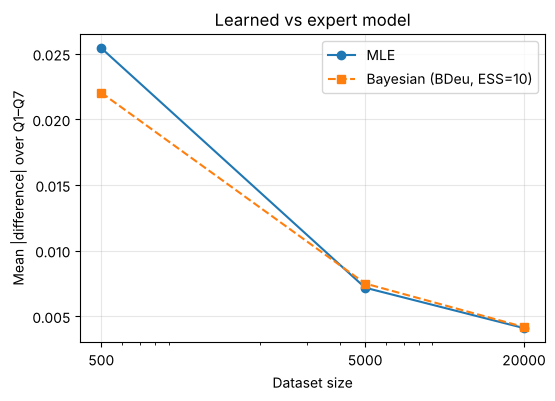

In [17]:
mad = pd.DataFrame({n: tables[n][["|Diff| MLE", "|Diff| Bayesian"]].mean() for n in SIZES}).T
display(mad.round(4))

plt.figure(figsize=(6, 4))
plt.plot(SIZES, mad["|Diff| MLE"], "o-", label="MLE")
plt.plot(SIZES, mad["|Diff| Bayesian"], "s--", label="Bayesian (BDeu, ESS=10)")
plt.xscale("log"); plt.xticks(SIZES, SIZES)
plt.xlabel("Dataset size"); plt.ylabel("Mean |difference| over Q1–Q7")
plt.title("Learned vs expert model"); plt.grid(alpha=.3); plt.legend(); plt.show()

In [18]:
# E2. Which query is worst at n = 500, and how much data backs its evidence?
t500 = tables[500]
evidence_count = {q: len(datasets[500].query(" and ".join(f"{k} == '{v}'" for k, v in ev.items())))
                  if ev else 500 for q, (_, _, ev) in QUERIES.items()}
t500 = t500.assign(**{"rows matching evidence": pd.Series(evidence_count)})
display(t500[["|Diff| MLE", "|Diff| Bayesian", "rows matching evidence"]].round(4))
print("Largest error (MLE):     ", t500["|Diff| MLE"].idxmax())
print("Largest error (Bayesian):", t500["|Diff| Bayesian"].idxmax())

,|Diff| MLE,|Diff| Bayesian,rows matching evidence
Q1,0.0016,0.0001,500
Q2,0.0404,0.0334,246
Q3,0.0176,0.0221,154
Q4,0.0472,0.0422,65
Q5,0.0228,0.0145,292
Q6,0.0312,0.0271,292
Q7,0.0173,0.0148,207


Largest error (MLE):      Q4
Largest error (Bayesian): Q4


### E2. Largest error at n = 500 → **Q4**, P(E=High | Weather=Cold, Occupancy=High)

Q4's evidence matches only **65 of 500 rows** — the rarest evidence of any query. Two consequences:

- The parameter it leans on, P(AC=On | Cold, High), is learned from those 65 rows, so it has the largest
  standard error of any AC cell (≈ √(0.1·0.9/65) ≈ 0.037).
- Fixing both Weather and Occupancy removes all averaging: Q4 is a product of a few specific estimates
  (P(Load | High), P(E | AC=Off, ·), P(AC | Cold, High)), so their errors add up instead of cancelling.
  In this run the AC cell happened to land close (0.092 vs 0.10), but P(Load=Heavy | High) (0.71 vs 0.75) and
  P(E=High | Off, Heavy) (0.51 vs 0.55) are both too low, and they push Q4 down together.

Q1 (all 500 rows, marginalises over everything) has the smallest error. The robustness check below confirms
this is systematic: over 30 seeds, Q4 is the worst query far more often than any other.

Note: the three datasets come from one seed, so each is a prefix of the next. At n ≥ 5000 the remaining gap
(e.g. Q1 ≈ 0.006) is sampling noise in the dataset itself — the learned models match the empirical
frequencies (empirical P(E=High) = 0.574 at n=20000) — and it shrinks like 1/√n.

In [19]:
# Robustness check: one dataset is one draw. Repeat the n=500 comparison over 30 different seeds.
mad_mle, mad_bayes, worst = [], [], []
for seed in range(1000, 1030):
    d = ancestral_sample(500, seed)
    err_mle = (run_queries(learn(d, "MLE")) - expert_answers).abs()
    err_bayes = (run_queries(learn(d, "Bayesian")) - expert_answers).abs()
    mad_mle.append(err_mle.mean()); mad_bayes.append(err_bayes.mean()); worst.append(err_mle.idxmax())

mad_mle, mad_bayes = np.array(mad_mle), np.array(mad_bayes)
print(f"Mean |Diff| over 30 seeds (n=500):  MLE {mad_mle.mean():.4f}   Bayesian {mad_bayes.mean():.4f}")
print(f"Bayesian better in {(mad_bayes < mad_mle).sum()}/30 seeds")
print("Worst query (MLE) per seed:", pd.Series(worst).value_counts().to_dict())

Mean |Diff| over 30 seeds (n=500):  MLE 0.0241   Bayesian 0.0239
Bayesian better in 17/30 seeds
Worst query (MLE) per seed: {'Q4': 13, 'Q7': 6, 'Q1': 3, 'Q2': 2, 'Q5': 2, 'Q6': 2, 'Q3': 2}


### E3. Which estimator is better for small datasets?

BDeu adds ESS / (parent configs × states) pseudo-counts to every CPT cell — for AC that is 10/12 ≈ 0.83 per cell —
which pulls each estimate slightly toward uniform. With little data this cuts variance and rules out 0/1
probabilities. The AC table shows it directly: at n = 500, MLE sets P(AC=On | Cold, Low) = **0.000** because
none of the 39 Cold/Low rows had the AC on — the model now claims that event is impossible — while BDeu gives 0.021.
On our 500-sample dataset this gives a modest gain (mean error 0.0220 vs 0.0254), and Bayesian wins on the
sparsest queries. But the effect is small: ESS = 10 is tiny next to 500 rows, and shrinking toward 0.5 adds bias
where the true values are extreme (0.90, 0.05); averaged over 30 seeds the two are essentially tied.
From 5000 rows on, the prior is swamped and both estimators give the same model. **Bayesian estimation is the
safer choice for small data — its advantage grows as rows per parent configuration approach zero — but at
n = 500 with ESS = 10 the difference here is marginal.**